# Introduction

# Part 1: Dataset

## 1.1. Importing Libraries

We will install the modules necessary for processing and splitting the dataset, as well as training different models.

In [1]:
%pip install xgboost scikit-optimize                # for BayesSearchCV

# Data Processing
import numpy as np
import pandas as pd
import re
import ast
import json

# Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Data Transformation
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler

# Cross-Validation
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

# Model Evaluation
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# Plot
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

## 1.2. Importing Dataset

We will pull our main table from the [OpenAlex API](https://docs.openalex.org), which is under CC0, using this [script](https://colab.research.google.com/drive/1fW5ZYzsfhuQTLiwYT-Fjuk_LviddvUXX?usp=sharing). We then join it with two other tables extracted from the Hugging Face API, `open-index/open-arxiv` (CC0) and [Papers with Code](https://huggingface.co/datasets/pwc-archive/links-between-paper-and-code) (CC-BY-SA), using this [script](https://colab.research.google.com/drive/1ASUN5w36f7FC300-ONni5fg_OeIWEmCp?usp=sharing).

In [2]:
# Load the joined dataset
papers_df = pd.read_parquet("https://www.dropbox.com/scl/fi/jolt6kfbslvla17m234pi/full_papers.parquet?rlkey=ohjrwo5oi8q1fsahue3gy9ccs&st=v72ugyvb&dl=1")

## 1.3. Analyzing Dataset

We will first analyze the structure of the data, including the data types and missing values.

In [3]:
# View the first 5 samples
papers_df.head(5)

,id,doi,title,abstract_inverted_index,publication_date,publication_year,counts_by_year,authorships,institutions_distinct_count,countries_distinct_count,...,language,arxiv_id,categories,versions,comments,journal-ref,update_date,license,num_repositories,has_code
0,https://openalex.org/W3003257820,https://doi.org/10.1038/s41592-019-0686-2,SciPy 1.0: fundamental algorithms for scientif...,"{'SciPy': [0, 18, 65], 'is': [1], 'an': [2, 56...",2020-02-03,2020,"[{'year': 2026, 'cited_by_count': 7041}, {'yea...","[{'author_position': 'first', 'author': {'id':...",84,18,...,en,1907.10121,cs.MS cs.DS cs.SE physics.comp-ph,"[{""version"":""v1"",""created"":""Tue, 23 Jul 2019 2...",Article source data is available here:\n http...,None,2020-09-18,http://creativecommons.org/licenses/by/4.0/,1,1
1,https://openalex.org/W2963163009,https://doi.org/10.1109/cvpr.2018.00474,MobileNetV2: Inverted Residuals and Linear Bot...,"{'In': [0], 'this': [1, 133, 143], 'paper': [2...",2018-06-01,2018,"[{'year': 2026, 'cited_by_count': 3194}, {'yea...","[{'author_position': 'first', 'author': {'id':...",1,1,...,en,1801.04381,cs.CV,"[{""version"":""v1"",""created"":""Sat, 13 Jan 2018 0...",,None,2019-03-25,http://arxiv.org/licenses/nonexclusive-distrib...,159,1
2,https://openalex.org/W3035965352,https://doi.org/10.1038/s41586-020-2649-2,Array programming with NumPy,"{'Abstract': [0], 'Array': [1], 'programming':...",2020-09-16,2020,"[{'year': 2026, 'cited_by_count': 4947}, {'yea...","[{'author_position': 'first', 'author': {'id':...",18,7,...,en,2006.10256,cs.MS stat.CO,"[{""version"":""v1"",""created"":""Thu, 18 Jun 2020 0...",,None,2020-09-22,http://creativecommons.org/licenses/by/4.0/,1,1
3,https://openalex.org/W2964309882,https://doi.org/10.1007/978-3-030-01234-2_49,Encoder-Decoder with Atrous Separable Convolut...,,2018-01-01,2018,"[{'year': 2026, 'cited_by_count': 2340}, {'yea...","[{'author_position': 'first', 'author': {'id':...",1,1,...,en,1802.02611,cs.CV,"[{""version"":""v1"",""created"":""Wed, 7 Feb 2018 19...",ECCV 2018 camera ready,None,2018-08-24,http://arxiv.org/licenses/nonexclusive-distrib...,78,1
4,https://openalex.org/W3030520226,https://doi.org/10.1007/978-3-030-58452-8_13,End-to-End Object Detection with Transformers,,2020-01-01,2020,"[{'year': 2026, 'cited_by_count': 2756}, {'yea...","[{'author_position': 'first', 'author': {'id':...",2,2,...,en,2005.12872,cs.CV,"[{""version"":""v1"",""created"":""Tue, 26 May 2020 1...",,None,2020-05-29,http://creativecommons.org/publicdomain/zero/1.0/,37,1


### 1.3.1. General View

In [4]:
# View the data types of each feature
papers_df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122136 entries, 0 to 122135
Data columns (total 29 columns):
 #   Column                       Non-Null Count   Dtype 
---  ------                       --------------   ----- 
 0   id                           122136 non-null  object
 1   doi                          122066 non-null  object
 2   title                        122136 non-null  object
 3   abstract_inverted_index      122136 non-null  object
 4   publication_date             122136 non-null  object
 5   publication_year             122136 non-null  int64 
 6   counts_by_year               122136 non-null  object
 7   authorships                  122136 non-null  object
 8   institutions_distinct_count  122136 non-null  int64 
 9   countries_distinct_count     122136 non-null  int64 
 10  referenced_works_count       122136 non-null  int64 
 11  referenced_works             122136 non-null  object
 12  primary_topic                122136 non-null  object
 13  topics        

**Initial Observations**:
- `journal-ref` is empty, so we can drop this column completely.
- Other features that have some missing values: `doi`, `versions`, `update_date`, and `license`
  - `publication_date` and `update_date` are stored as string instead of a datetime object

### 1.3.2. Checking Duplicates

Check that the dataset doesn't contain multiple records for the same arXiv ID and that the join didn't duplicate papers.

In [5]:
# Check for records that share the same arXiv ID
print("Total rows:", len(papers_df))
print("Unique arXiv IDs:", papers_df["arxiv_id"].nunique())
print("Duplicate arXiv IDs:", papers_df["arxiv_id"].duplicated().sum())

# Check for duplicate rows
papers_df[papers_df.duplicated(keep=False)]

Total rows: 122136
Unique arXiv IDs: 122136
Duplicate arXiv IDs: 0


,id,doi,title,abstract_inverted_index,publication_date,publication_year,counts_by_year,authorships,institutions_distinct_count,countries_distinct_count,...,language,arxiv_id,categories,versions,comments,journal-ref,update_date,license,num_repositories,has_code


### 1.3.3. Data Type of Nested Columns

`.info()` only give the data type `object` for non-numerical features. We will closely examine the data type these columns, especially those with nested columns.

In [6]:
columns = ["abstract_inverted_index", "counts_by_year", "authorships",
           "referenced_works", "primary_topic", "topics", "versions", "open_access"]

for col in columns:
    print(f"{col}: {type(papers_df[col].iloc[0])}")

abstract_inverted_index: <class 'str'>
counts_by_year: <class 'str'>
authorships: <class 'str'>
referenced_works: <class 'str'>
primary_topic: <class 'str'>
topics: <class 'str'>
versions: <class 'str'>
open_access: <class 'str'>


**Issue**: The above features are supposed to be a `list` of values, but they are stored as string.

### 1.3.4. Missing Values

Even though the `categories` and `comments` columns contain no null values, since they are stored as string, the null values may be represented as an empty string.

In [7]:
print('categories')
print(f"Empty strings: {(papers_df['categories'] == "").sum()}\n")
print('comments')
print(f"Empty strings: {(papers_df['comments'] == "").sum()}")

categories
Empty strings: 39

comments
Empty strings: 46894


### 1.3.5. Unique Values

We will examine the number of unique values of non-numerical columns to decide a preprocessing method.

In [8]:
# See the number of unique values for each feature in the dataset
for col in papers_df:
    print(f'{col}: {papers_df[col].nunique():,}')

id: 122,136
doi: 122,065
title: 122,096
abstract_inverted_index: 108,279
publication_date: 1,096
publication_year: 3
counts_by_year: 65,142
authorships: 120,659
institutions_distinct_count: 37
countries_distinct_count: 19
referenced_works_count: 372
referenced_works: 112,169
primary_topic: 49,397
topics: 107,431
open_access: 122,135
locations: 122,136
locations_count: 26
primary_location: 122,136
type: 22
language: 22
arxiv_id: 122,136
categories: 10,156
versions: 122,064
comments: 52,172
journal-ref: 0
update_date: 2,700
license: 8
num_repositories: 75
has_code: 2


We found several high-cardinality, non-numerical features that can cause issues during the one-hot encoding procedure: `abtract_inverted_index`, `publication_date`, `counts_by_year` (**TARGET**), `authorships`, `referenced_works`, `primary_topic`, `topics`, `open_access`, `locations`, `primary_location`, `categories`, `versions`, `comments`, and `update_date`.

To fix this issue, we will drop non-numerical features that do not contain meaningful information or convert them into numerical features.

# Part 2: Preprocessing Dataset

## 2.1. Dropping Columns

We will drop the following columns:
- `journal-ref` - Empty column
- `id`, `doi`, and `arxiv_id` - Unique identifiers that are unnecessary data and can cause noise
- `update_date`- Represents the latest metadata update, not the initial submission date
- `locations` - This column was used to extract a paper's arXiv ID, but `locations_count` is a sufficient numerical representation of it
- `referenced_works` - Its detailed information is unnecessary, as the `referenced_works_count` is a sufficient numerical representation of it

In [9]:
cleaned_papers_df = papers_df.copy()

# Drop unnecessary columns
cleaned_papers_df.drop(labels=['journal-ref', 'id', 'doi', 'arxiv_id', 'update_date',
                               'locations', 'referenced_works'],
                       axis=1, inplace=True)

## 2.2. Feature Engineering

Since there exist high-cardinality, non-numerical features, we will engineer features from them to resolve the issues.

**Note**: Since there exist nested columns that are stored as strings, we need to use `ast.literal_eval()` to convert them to lists to be used for analysis, extraction, and engineering features.

### 2.2.1. cites_3yr

As mentioned above, our target, `counts_by_year`, is a list of citations, but it is stored as a string. Hence, we will parse this column into lists.

In [10]:
cleaned_papers_df['counts_by_year'] = cleaned_papers_df['counts_by_year'].apply(lambda x: ast.literal_eval(x))

Compute `cites_3yr` by extracting the year-to-citation-count mapping and summing the three relevant years.

<u>Note:</u> If OpenAlex omits a year in `counts_by_year`, this means that the paper received **zero** citations in that year.

In [11]:
def calculate_cites_3yr(row):
    counts = row["counts_by_year"]
    year = row["publication_year"]

    if pd.isna(year):
        return np.nan
    citation_dict = {item["year"]: item["cited_by_count"] for item in counts}
    return sum(citation_dict.get(y, 0) for y in range(int(year), int(year) + 3))

cleaned_papers_df["cites_3yr"] = cleaned_papers_df.apply(calculate_cites_3yr, axis=1)
cleaned_papers_df.drop('counts_by_year', axis=1, inplace=True)

### 2.2.2. Date

Publication Month

In addition to the publication year, we also want to use a paper's publication month as a predictor, which is extracted from `publication_date`. This date affects when the paper gains official visibility and starts accumulating formal citations.

In [12]:
# Convert strings into datetime objects
cleaned_papers_df["publication_date"] = pd.to_datetime(cleaned_papers_df["publication_date"], errors="coerce")

# Extract the month from the datetime objects
cleaned_papers_df["publication_month"] = cleaned_papers_df["publication_date"].dt.month

Submission Month

The `versions` column may contain a list of version records with timestamps. Extract the first version, which will contain the month of the submission.

Many field have massive spikes in submissions right before major conference deadlines. Papers submitted during these rush periods might have different citation trajectories or characteristics than off-season submissions.

In [13]:
def get_first_submission(x):
    if not isinstance(x, str) or pd.isna(x):
        return None
    versions = ast.literal_eval(x)
    if versions:
        return versions[0].get("created")
    return None

first_submission = cleaned_papers_df['versions'].apply(get_first_submission)
first_submission_date = pd.to_datetime(first_submission, errors="coerce")
cleaned_papers_df["submission_month"] = first_submission_date.dt.month

cleaned_papers_df.drop('versions', axis=1, inplace=True)

### 2.2.3. Time Gap

Using `publication_date` and `first_submission_date`, we can derived the `time_to_publish`. A long gap between submission might indicate a rigorous peer-review process, multiple revisions, or a prestigious journal, which could be a strong predictor.

In [14]:
cleaned_papers_df['time_to_publish'] = (cleaned_papers_df['publication_date'] - first_submission_date).dt.days

cleaned_papers_df.drop('publication_date', axis=1, inplace=True)

Check whether `time_to_publish` contains negative values.

In [15]:
print(f"Negative Time Gap: {len(cleaned_papers_df[cleaned_papers_df['time_to_publish'] < 0])}")

Negative Time Gap: 76339


Because variable `first_submission_date` comes from the paper's first arXiv version and `publication_date` comes from OpenAlex (the official journal/conference date), a negative value means that the paper was officially published **before** it was uploaded to arXiv. This happens frequently when researchers upload "post-prints" to arXiv after their paper has already been accepted or published, or when a conference date precedes the arXiv upload.

To capture these distinct timing dynamics and avoid passing raw negative days into the model, we engineer two separate, non-negative features:
- `pub_after_arxiv_days` = This clips the time gap at a minimum of `0`. It measures the formal wait time from public preprint release on arXiv to official publication. For papers published before being posted to arXiv, this is reasonably treated as `0` days.
- `arxiv_after_pub_days` = This measures the delay in posting a paper to arXiv *after* it has already been officially published. This captures "post-print" posting behavior, which often has a different social or citation dynamic compared to preprints.

In [16]:
cleaned_papers_df['pub_after_arxiv_days'] = cleaned_papers_df['time_to_publish'].clip(lower=0)
cleaned_papers_df['arxiv_after_pub_days'] = (-cleaned_papers_df['time_to_publish']).clip(lower=0)

cleaned_papers_df.drop('time_to_publish', axis=1, inplace=True)

### 2.2.4. Authorships

OpenAlex `authorships` is a list of the authorship records (e.g., names, positions, institutions, countries). To represent the academic influence, diversity, and geographical footprint of a paper, we engineer the following features:
- `author_count` = The total number of co-authors on the paper. Larger collaboration networks may expand a paper's initial reach and increase citation probability.
- `has_company_author` = A binary flag (`1` or `0`) indicating whether at least one author is affiliated with an industry/company institution. Corporate backing and collaborative research can point to strong real-world applications or resources, often accelerating citation rates.
- `first_author_country` = The country of affiliation for the first author. This controls for regional publishing patterns, language familiarity, and geographically clustered academic networks.

In [17]:
authorships = cleaned_papers_df['authorships'].apply(ast.literal_eval)
cleaned_papers_df.drop('authorships', axis=1, inplace=True)

cleaned_papers_df["author_count"] = authorships.apply(lambda x: len(x))
cleaned_papers_df["has_company_author"] = authorships.apply(
    lambda a: int(any(i.get("type") == "company" for x in a for i in (x.get("institutions") or []))))
cleaned_papers_df["first_author_country"] = authorships.apply(
    lambda a: next((x["countries"][0] for x in a
                    if x.get("author_position") == "first" and x.get("countries")), "unknown"))

### 2.2.5. Title & Abstract Length

To capture paper complexity, readability, and information density, we extract text-length features:
- `title_length` = The number of words in the title. Shorter, punchier titles might be more memorable, while longer ones can be highly descriptive.
- `abstract_length` = Computed by reconstructively summing the length of word position indexes within `abstract_inverted_index`. Shorter abstracts might indicate concise summaries, whereas longer ones could signify highly detailed or interdisciplinary work.

In [18]:
# Title Length
cleaned_papers_df['title_length'] = cleaned_papers_df['title'].apply(lambda x: len(x.split()))
cleaned_papers_df.drop('title', axis=1, inplace=True)

# Abstract Length
def get_abstract_length(x):
    if not isinstance(x, str) or x == "":
        return 0
    abstract = ast.literal_eval(x)
    return sum(len(positions) for positions in abstract.values())

cleaned_papers_df['abstract_length'] = cleaned_papers_df['abstract_inverted_index'].apply(get_abstract_length)
cleaned_papers_df.drop('abstract_inverted_index', axis=1, inplace=True)

### 2.2.6. Category

To capture a paper's scientific domain and interdisciplinary scope, we engineer two features from the arXiv categories:
- `category_count` = The total number of subcategories a paper is tagged with. This measures its level of interdisciplinarity (e.g., crossing computer science with physics).
- `primary_category` = The first category in the listed tags, representing the primary home or focus of the paper.

In [19]:
cats = cleaned_papers_df["categories"].str.split()
cleaned_papers_df.drop('categories', axis=1, inplace=True)

cleaned_papers_df['category_count'] = cats.apply(lambda x: len(x))
cleaned_papers_df['primary_category'] = cats.str[0].fillna("unknown")

### 2.2.7. Venue

The `primary_location` dictionary provides information about where a paper was formally published. From this nested metadata, we extract the venue classification:
- `venue_type` = Represents the category of the publishing source (e.g., `'journal'`, `'repository'`, `'conference'`). Different publishing formats have distinct review standards, audience reaches, and propagation speeds, which strongly influence the long-term and short-term citation trajectories of the paper.

In [20]:
# Publisher / venue
primary_location = papers_df['primary_location'].apply(ast.literal_eval)
cleaned_papers_df['venue_type'] = primary_location.apply(lambda d: ((d or {}).get("source") or {}).get("type") or "unknown")

cleaned_papers_df.drop('primary_location', axis=1, inplace=True)

### 2.2.8. Topics & Primary Topic

These features capture the overall domain context and theme density defined by OpenAlex:
- `n_subfields` = Represents the number of unique subfields a paper spans based on its topic tags. This acts as a proxy for topic breadth.
- `primary_subfield` = The name of the main subfield associated with the paper's primary topic, helping the model learn field-specific citation baselines.

In [21]:
# Topics
topics = cleaned_papers_df['topics'].apply(ast.literal_eval)
cleaned_papers_df.drop('topics', axis=1, inplace=True)
cleaned_papers_df['n_subfields'] = topics.apply(lambda t: len({x["subfield"]["display_name"] for x in t if x.get("subfield")}))

# Primary Topic
primary_topic = cleaned_papers_df['primary_topic'].apply(ast.literal_eval)
cleaned_papers_df.drop('primary_topic', axis=1, inplace=True)
cleaned_papers_df["primary_subfield"] = primary_topic.apply(lambda x: x.get('subfield').get('display_name'))

### 2.2.9. Comments

The `comments` column contains unstructured metadata appended to the preprint submission. To leverage this unstructured text, we extract structural information:
- `page_count` = Extracted by searching for page-related patterns (e.g., "12 pages"). The overall length of a manuscript is a strong proxy for detail, density of information, and type of paper (such as brief communication vs. full-length monograph), which directly scales with citation frequency.

In [22]:
comments = cleaned_papers_df["comments"].fillna("")
cleaned_papers_df.drop('comments', axis=1, inplace=True)

cleaned_papers_df["page_count"] = pd.to_numeric(comments.str.extract(r"(\d+)\s*pages?", flags=re.I)[0])

### 2.2.10. Accessibility

Open access directly influences how easily other researchers can read and reference a manuscript. From the `open_access` nested metadata, we extract:
- `is_oa` = A binary flag indicating whether the paper is openly readable. Lowering paywall barriers is heavily associated with higher download rates and increased early-stage citation velocity.
- `oa_status` = Categorical classification of the open access path (e.g., gold, green, bronze, hybrid, closed). This helps capture publishing routes, publisher fees, and repository compliance patterns.
- `any_repository_has_fulltext` = A binary flag showing if a green open access version is archived elsewhere. This serves as a strong signal of manuscript discoverability outside of traditional publisher portals.

In [23]:
oa_cols = ["is_oa", "oa_status", "any_repository_has_fulltext"]

for col in oa_cols:
    cleaned_papers_df[col] = cleaned_papers_df["open_access"].apply(
        lambda x: (ast.literal_eval(x)).get(col)
    )
binary_cols = ['is_oa', 'any_repository_has_fulltext']
cleaned_papers_df[binary_cols] = cleaned_papers_df[binary_cols].astype("float64")

cleaned_papers_df.drop('open_access', axis=1, inplace=True)

### 2.2.11. Cleaning

In [24]:
cleaned_papers_df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122136 entries, 0 to 122135
Data columns (total 29 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   publication_year             122136 non-null  int64  
 1   institutions_distinct_count  122136 non-null  int64  
 2   countries_distinct_count     122136 non-null  int64  
 3   referenced_works_count       122136 non-null  int64  
 4   locations_count              122136 non-null  int64  
 5   type                         122136 non-null  object 
 6   language                     122136 non-null  object 
 7   license                      122096 non-null  object 
 8   num_repositories             122136 non-null  int64  
 9   has_code                     122136 non-null  int64  
 10  cites_3yr                    122136 non-null  int64  
 11  publication_month            122136 non-null  int32  
 12  submission_month             122097 non-null  float64
 13 

Since `page_count` is missing ~70% of its data, we will drop this column.

In [25]:
cleaned_papers_df.drop('page_count', axis=1, inplace=True)

We observed that `license` is missing 40 values, while `submission_month`, `pub_after_arxiv_days`, and `arxiv_after_pub_days` are missing 39 values. First, we will check whether the missing values overlap.

In [26]:
cols = ["license", "submission_month", "pub_after_arxiv_days", "arxiv_after_pub_days"]

print(cleaned_papers_df[cols].isna().sum())
print("\nMissing-value combinations:")
print(cleaned_papers_df[cols].isna().value_counts())

license                 40
submission_month        39
pub_after_arxiv_days    39
arxiv_after_pub_days    39
dtype: int64

Missing-value combinations:
license  submission_month  pub_after_arxiv_days  arxiv_after_pub_days
False    False             False                 False                   122096
True     True              True                  True                        39
         False             False                 False                        1
Name: count, dtype: int64


The `Missing-value combinations` table tells us that there are 39 papers that are missing data for *all four* columns at the same time, and there's 1 paper that is missing a `license` but contains both `submission_month`, `pub_after_arxiv_days`, and `arxiv_after_pub_days`.

Since `license` is a non-numerical feature, we can use one-hot encoding on it, which can handle null values. However, `submission_month`, `pub_after_arxiv_days`, and `arxiv_after_pub_days` are numerical features, so we will need to impute these missing values with their respective medians.

In [27]:
# Impute missing values with medians
for col in ['submission_month', 'pub_after_arxiv_days', 'arxiv_after_pub_days']:
    cleaned_papers_df[col] = cleaned_papers_df[col].fillna(cleaned_papers_df[col].median())

Check the cardinality of all features.

In [28]:
# List of categorical and numerical features to be used for model training
categorical_cols = ['type', 'language', 'license', 'oa_status', 'primary_subfield',
                    'primary_category', 'venue_type', 'first_author_country']
numerical_cols = [col for col in cleaned_papers_df if col not in categorical_cols
                  and col != 'cites_3yr']

In [29]:
# Check the number of unique values for categorical features in the dataset
for col in categorical_cols:
    print(f'{col}: {cleaned_papers_df[col].nunique():,}')

type: 22
language: 22
license: 8
oa_status: 5
primary_subfield: 11
primary_category: 146
venue_type: 6
first_author_country: 126


Observations:
- The only high-cardinality features are `primary_category` and `first_author_country`
- The remaining categorical features are of low-cardinality, so we can one-hot encode them

Even if they are of high-cardinality, these features contain valuable information which can influence the number of citations a paper receive. Hence, we will group categories and countries with low-frequency (e.g., values that appear in 100 or less papers) into a single label "Other". This approach helps control feature explosion during one-hot encoding, prevents overfitting on rare categories, and preserves the predictive value of highly frequent levels.

In [30]:
counts = cleaned_papers_df['first_author_country'].value_counts()
print(counts.head(10))

cleaned_papers_df['first_author_country'] = (
    cleaned_papers_df['first_author_country']
    .where(cleaned_papers_df['first_author_country'].map(counts) >= 100, "Other")
)
print(f"first_author_country: {cleaned_papers_df['first_author_country'].nunique()}")

first_author_country
unknown    28051
US         27645
CN         12345
DE          6403
GB          5822
FR          3676
CA          3571
IN          2777
JP          2580
AU          2425
Name: count, dtype: int64
first_author_country: 50


In [31]:
counts = cleaned_papers_df['primary_category'].value_counts()
print(counts.head(10))

cleaned_papers_df['primary_category'] = (
    cleaned_papers_df['primary_category']
    .where(cleaned_papers_df['primary_category'].map(counts) >= 100, "Other")
)
print(f"primary_category: {cleaned_papers_df['primary_category'].nunique()}")

primary_category
cs.CV       19505
cs.LG       17428
cs.CL       10808
quant-ph     7804
cs.CR        5005
cs.DC        3268
cs.AI        3237
cs.IT        3212
stat.ML      3195
cs.DS        3142
Name: count, dtype: int64
primary_category: 73


In [32]:
# Check the number of unique values for numerical features in the dataset
for col in numerical_cols:
    print(f'{col}: {cleaned_papers_df[col].nunique():,}')

publication_year: 3
institutions_distinct_count: 37
countries_distinct_count: 19
referenced_works_count: 372
locations_count: 26
num_repositories: 75
has_code: 2
publication_month: 12
submission_month: 12
pub_after_arxiv_days: 1,657
arxiv_after_pub_days: 1,493
author_count: 72
has_company_author: 2
title_length: 34
abstract_length: 485
category_count: 9
n_subfields: 3
is_oa: 1
any_repository_has_fulltext: 1


However, `is_oa`, and `any_repository_has_fulltext` each only has 1 unique value, which won't be useful as predictors. Thus, we will drop these columns.

In [33]:
cleaned_papers_df.drop(['is_oa', 'any_repository_has_fulltext'], axis=1, inplace=True)

In [34]:
# Update numerical_cols
numerical_cols = [col for col in cleaned_papers_df if col not in categorical_cols
                  and col != 'cites_3yr']

# Set up an ablation set
leak_cols = ["has_code", "num_repositories", "locations_count"]
feature_sets = {"main":       [c for c in numerical_cols if c not in leak_cols],
                "with_leaky": numerical_cols}

print(f"Total Features: {len(categorical_cols + numerical_cols)}")

Total Features: 25


# Part 3: Exploratory Data Analysis

## 3.1. Target Variable

We will first analyze the target variable, `cites_3yr`, to better understand our objective.

In [35]:
cleaned_papers_df["cites_3yr"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(4)

,cites_3yr
count,122136.0000
mean,16.2092
std,78.2087
min,0.0000
25%,1.0000
50%,4.0000
75%,13.0000
90%,34.0000
95%,62.0000
99%,183.0000


We will then plot its distribution.

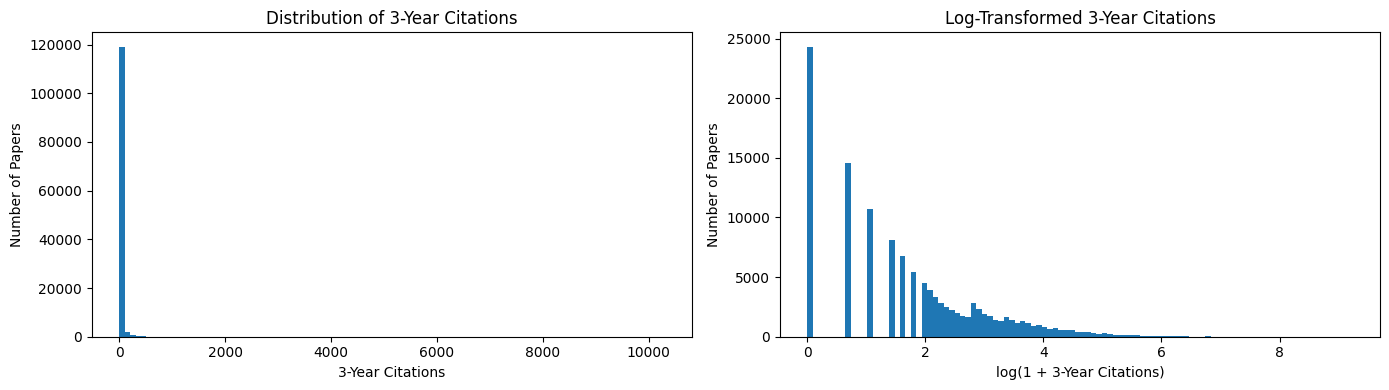

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Original distribution
axes[0].hist(cleaned_papers_df["cites_3yr"], bins=100)
axes[0].set_title("Distribution of 3-Year Citations")
axes[0].set_xlabel("3-Year Citations")
axes[0].set_ylabel("Number of Papers")

# Log-transformed distribution
axes[1].hist(np.log1p(cleaned_papers_df["cites_3yr"]), bins=100)
axes[1].set_title("Log-Transformed 3-Year Citations")
axes[1].set_xlabel("log(1 + 3-Year Citations)")
axes[1].set_ylabel("Number of Papers")

plt.tight_layout()
plt.show()

In the original plot (left), note that the citation is heavily **right-skewed**. A vast majority of papers receive zero or very few citations, creating a massive spike at the far left, while only a handfuul of outlier papers receive thousands of citations.

Because of this extreme skew, we want to **log-transform** the target variable, which shrinks those extreme outliers (without breaking the overall trend) and makes the underlying distribution much easier to read and model.

## 3.2. Numerical Features

Similar to analyzing the target variable, we will first inspect the numerical features' overall statistics and plot their their distributions.

In [37]:
# Exclude the binary features
binary_cols = ['has_code', 'has_company_author']

cleaned_papers_df[numerical_cols].drop(binary_cols, axis=1).describe().T

,count,mean,std,min,25%,50%,75%,max
publication_year,122136.0,2019.141834,0.803654,2018.0,2018.0,2019.0,2020.0,2020.0
institutions_distinct_count,122136.0,1.730718,1.648108,0.0,1.0,1.0,2.0,92.0
countries_distinct_count,122136.0,1.150611,0.855090,0.0,1.0,1.0,2.0,29.0
referenced_works_count,122136.0,30.042870,26.838173,0.0,14.0,26.0,40.0,966.0
locations_count,122136.0,3.462173,1.468015,1.0,2.0,3.0,4.0,28.0
num_repositories,122136.0,0.441770,2.769634,0.0,0.0,0.0,0.0,534.0
publication_month,122136.0,6.206065,3.622195,1.0,3.0,6.0,10.0,12.0
submission_month,122136.0,6.659961,3.359210,1.0,4.0,7.0,10.0,12.0
pub_after_arxiv_days,122136.0,94.852812,213.042094,0.0,0.0,0.0,103.0,9121.0
arxiv_after_pub_days,122136.0,35.913809,156.985754,0.0,0.0,1.0,1.0,2859.0


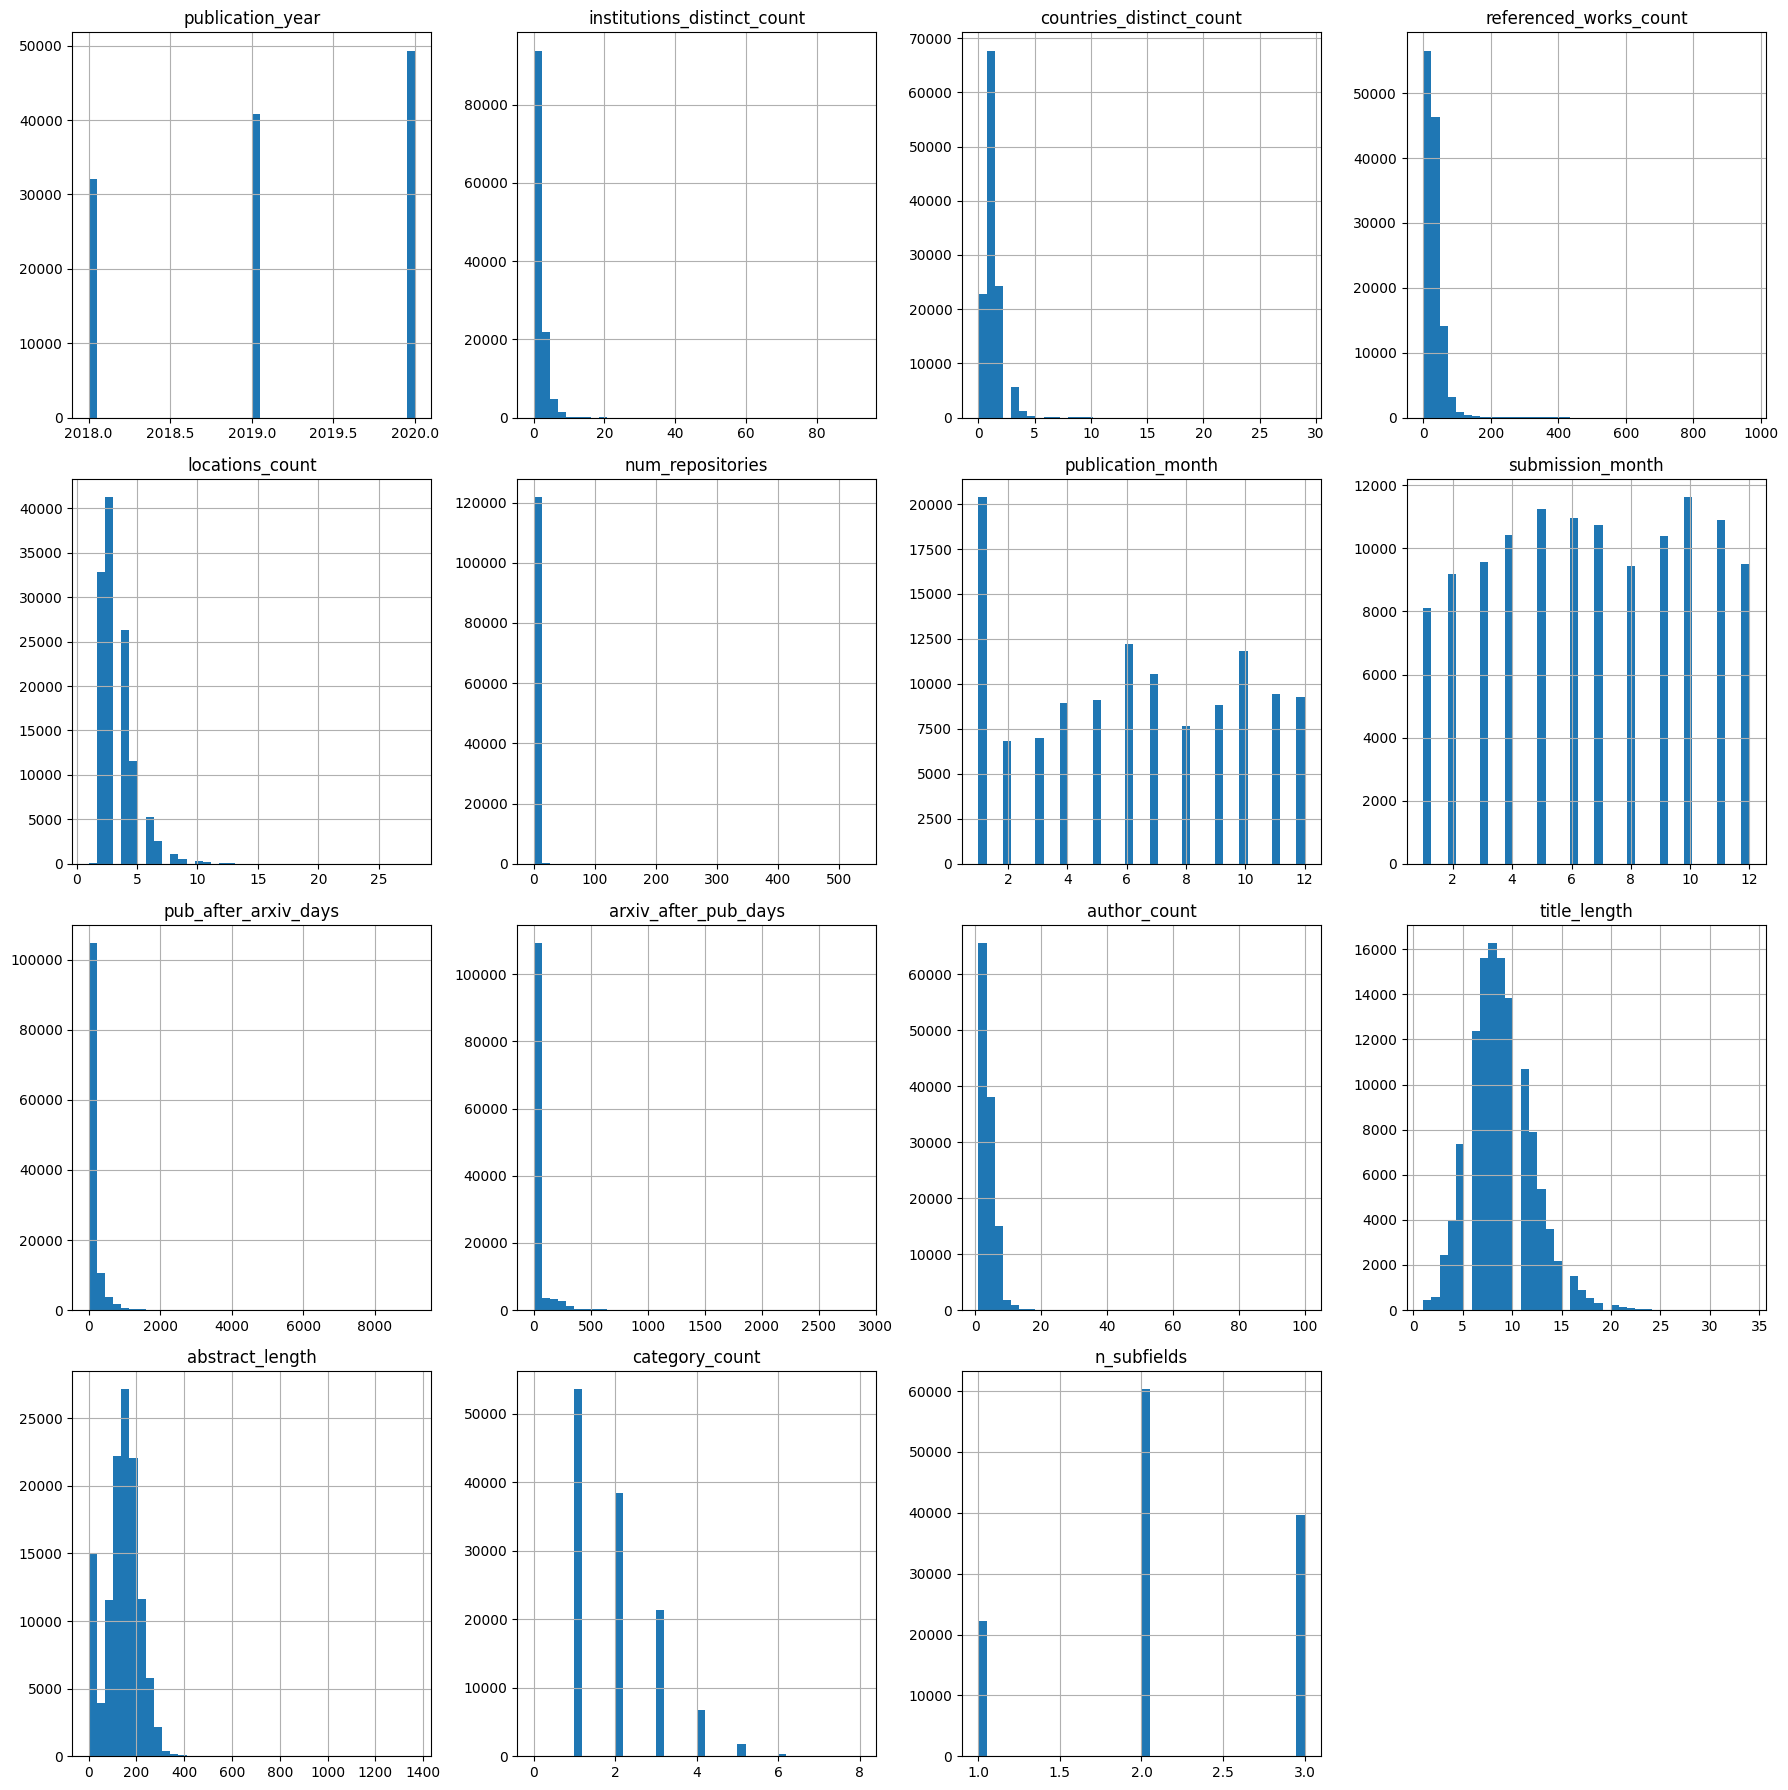

In [38]:
# Plot histograms
cleaned_papers_df[numerical_cols].drop(binary_cols, axis=1).hist(bins=40,figsize=(18, 18))
plt.tight_layout()
plt.show()

We will use the **Interquartile Range** (IQR) to detect and count the outliers in each of the numerical features.

In [39]:
outlier_results = []

non_binary_cols = [c for c in numerical_cols if c not in['has_code', 'has_company_author']]

for col in non_binary_cols:
    q1 = cleaned_papers_df[col].quantile(0.25)
    q3 = cleaned_papers_df[col].quantile(0.75)
    iqr = q3 - q1

    # Values that are below lower_bound or above upper_bound are outliers
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = cleaned_papers_df[
        (cleaned_papers_df[col] < lower_bound) |
        (cleaned_papers_df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(cleaned_papers_df) * 100,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound
    })

outlier_df = pd.DataFrame(outlier_results)
outlier_df.sort_values("Outlier Percentage", ascending=False)

,Feature,Outlier Count,Outlier Percentage,Lower Bound,Upper Bound
5,num_repositories,28424,23.272418,0.0,0.0
9,arxiv_after_pub_days,18069,14.794164,-1.5,2.5
8,pub_after_arxiv_days,15226,12.466431,-154.5,257.5
1,institutions_distinct_count,13428,10.994301,-0.5,3.5
13,category_count,8889,7.277952,-0.5,3.5
3,referenced_works_count,3614,2.958997,-25.0,79.0
4,locations_count,2269,1.857765,-1.0,7.0
10,author_count,2249,1.841390,-2.5,9.5
2,countries_distinct_count,1598,1.308378,-0.5,3.5
11,title_length,1394,1.141351,1.0,17.0


**Help**: Handle the outliers

<u>Idea:</u> Use `log1p` on the skewed features (except the binary ones)

## 3.3. Correlation Matrix

We will use a **correlation matrix** to identify features that are highly correlated with each other and decide which columns to be used for our models.

In [40]:
correlation_matrix = cleaned_papers_df.corr(numeric_only=True)

# Plot heatmap of correlation matrix
fig = go.Figure(data=go.Heatmap(
   z=correlation_matrix,
   x=correlation_matrix.columns,
   y=correlation_matrix.index,
   colorscale='RdBu_r',
   text=correlation_matrix.round(2),
   texttemplate='%{text}',
   textfont={"size": 10},
   hoverongaps=False,
   zmin=-1
))

fig.update_layout(
   width=900,
   height=900,
   title='Correlation Matrix Heatmap',
   xaxis_title='',
   yaxis_title='',
   yaxis=dict(autorange='reversed')
)

**Help**: Resolve the high correlation